# 02 · Preprocesamiento y preparación de datos

Este notebook documenta **cómo se llega del historial on-chain al dataset modelable** y verifica, con las funciones de
`src/data_processing.py`, que el dataset cumple todas las reglas antes de entrenar.

| Etapa | Script (en `functions/scripts/`) | Resultado |
|---|---|---|
| 1. Etiquetas | `screen-risk-wallets.mjs blacklist-*` | Fecha de inclusión de cada wallet en la blacklist de Tether |
| 2. Cohortes | `prepare-positive-cohort.py`, `prepare-risk-set-controls-v5.mjs` | Casos + controles activos en la misma fecha índice (risk set) |
| 3. Historial | `fetch-onchain-history.mjs`, `consolidate-onchain-history.mjs` | Transferencias USDT/TUSD de 90 días previas a la fecha índice |
| 4. Variables | `build-onchain-features.mjs` | 38 variables por wallet; mismas fórmulas que la API en vivo |
| 5. Partición | `split-positive-cases.py`, `assemble-risk-set-dataset.py` | Train/validación/test cronológicos por grupo + holdout externo |

Los datos crudos (≈ GB de eventos) no se versionan; ver `data/README.md`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data_processing import (FEATURE_NAMES, DataValidationError, address_overlap, balanced_sample_weights,
                                 groups_crossing_splits, load_dataset, log1p_clip, validate_dataset)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETA = {0: "#3b82c4", 1: "#e0663a"}
NOMBRES = {0: "Control (legítima)", 1: "Caso (blacklist después)"}
FIG = ROOT / "results" / "figures" / "eda"
MET = ROOT / "results" / "metrics"
FIG.mkdir(parents=True, exist_ok=True)
MET.mkdir(parents=True, exist_ok=True)

dev = load_dataset(ROOT / "data/processed/development_dataset_v6.csv")
ext = load_dataset(ROOT / "data/processed/external_holdout_v6.csv")
dev["indexAtUtc"] = pd.to_datetime(dev["indexAtUtc"])
ext["indexAtUtc"] = pd.to_datetime(ext["indexAtUtc"])
train = dev[dev.datasetSplit == "train"].copy()
print(f"Desarrollo: {dev.shape} · holdout externo: {ext.shape} · variables: {len(FEATURE_NAMES)}")

2026-10-23 10:29:54,874 INFO src.data_processing: Dataset development_dataset_v6.csv: 1854 filas, 44 columnas


2026-10-23 10:29:54,890 INFO src.data_processing: Dataset external_holdout_v6.csv: 286 filas, 44 columnas


Desarrollo: (1854, 44) · holdout externo: (286, 44) · variables: 38


## 1. Validación automática del dataset

In [2]:
for nombre, frame in [("desarrollo", dev), ("holdout externo", ext)]:
    print(nombre, validate_dataset(frame))
print("Grupos que cruzan particiones:", len(groups_crossing_splits(dev)))
print("Wallets compartidas desarrollo ↔ holdout:", len(address_overlap(dev, ext)))
casos = set(dev.loc[dev.target == 1, "address"])
controles = set(dev.loc[dev.target == 0, "address"])
print("Wallets que son caso y control a la vez:", len(casos & controles))

desarrollo {'rows': 1854, 'positives': 400, 'controls': 1454, 'groups': 400, 'splits': {'train': 1294, 'test': 282, 'validation': 278}}
holdout externo {'rows': 286, 'positives': 99, 'controls': 187, 'groups': 99, 'splits': {'external_holdout': 286}}
Grupos que cruzan particiones: 0
Wallets compartidas desarrollo ↔ holdout: 0
Wallets que son caso y control a la vez: 0


La validación también **rechaza** datasets con problemas; por ejemplo, una variable que filtre la etiqueta:

In [3]:
prueba = dev.head(20).copy()
prueba["blacklistFlag"] = prueba.target
try:
    validate_dataset(prueba)
except DataValidationError as error:
    print("Rechazado:", error.problems)

Rechazado: ['variables prohibidas (fuga de etiqueta): blacklistFlag']


## 2. Datos faltantes

No hay valores faltantes porque las variables se calculan de eventos completos. La política de faltantes está **en la
construcción**, no en una imputación:

* Una wallet con historial incompleto (TronGrid truncado o paginación excedida) se **excluye** del entrenamiento y en
  producción responde `NOT_SCORABLE` (`HISTORY_TRUNCATED`).
* Una wallet sin transferencias en la ventana es `NOT_SCORABLE` (`INSUFFICIENT_HISTORY`).
* El Workshop S5 mostró por qué no se imputa: imputar 10 % de valores con la mediana baja el recall de 0,80 a 0,64.

In [4]:
print("Faltantes por variable (desarrollo):", int(dev[FEATURE_NAMES].isna().sum().sum()))
print("Valores no finitos:", int((~np.isfinite(dev[FEATURE_NAMES].to_numpy(float))).sum()))
manifest = pd.read_json(ROOT / "data/processed/development_manifest_v6.json", typ="series")
{k: manifest[k] for k in ["rows", "positives", "controls", "temporalMismatches", "nonFiniteFeatureValues",
                          "caseControlAddressOverlap", "externalHoldoutDevelopmentOverlap"]}

Faltantes por variable (desarrollo): 0
Valores no finitos: 0


{'rows': 1854,
 'positives': 400,
 'controls': 1454,
 'temporalMismatches': 0,
 'nonFiniteFeatureValues': 0,
 'caseControlAddressOverlap': 0,
 'externalHoldoutDevelopmentOverlap': 0}

## 3. Desbalance de clases

El diseño caso-control fija entre 2 y 4 controles por caso. Se compensa con **pesos balanceados** dentro de cada `fit`
(`balanced_sample_weights`): cada clase aporta la misma masa total a la función de pérdida. No se usa sobremuestreo (SMOTE)
porque generaría wallets sintéticas sin semántica on-chain y mezclaría información entre grupos emparejados.

In [5]:
y = train.target.to_numpy()
w = balanced_sample_weights(y)
print("Controles por caso:", manifest["controlsPerCaseDistribution"])
print(f"Peso de un caso: {w[y == 1][0]:.3f} · peso de un control: {w[y == 0][0]:.3f}")
print(f"Masa total casos: {w[y == 1].sum():.1f} · masa total controles: {w[y == 0].sum():.1f}")

Controles por caso: {'2': 21, '3': 104, '4': 275}
Peso de un caso: 2.311 · peso de un control: 0.638
Masa total casos: 647.0 · masa total controles: 647.0


## 4. Escalado y transformaciones

* **Modelo principal (árboles):** sin escalado ni transformaciones. Un stump solo compara `x <= umbral`, así que cualquier
  transformación monótona da el mismo modelo, y la API calcula las variables en su escala natural.
* **Baseline lineal:** `log1p` con recorte en 0 + `StandardScaler`, porque la regresión logística sí es sensible a la escala
  y la asimetría extrema dominaría los coeficientes.

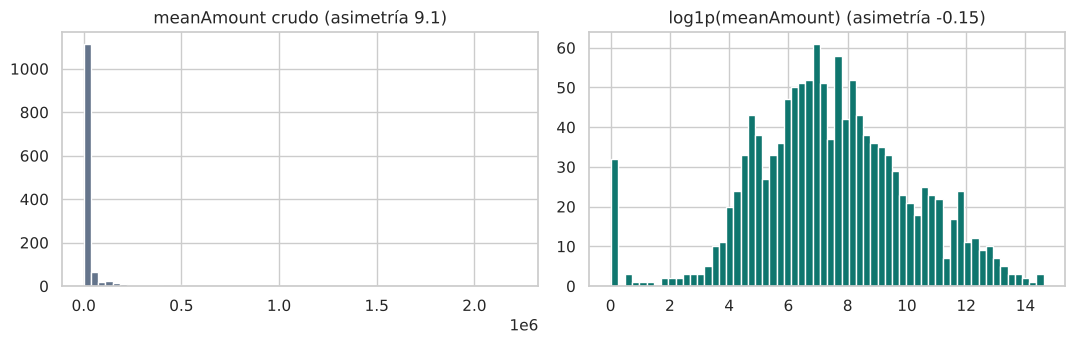

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(train.meanAmount, bins=60, color="#64748b")
axes[0].set_title(f"meanAmount crudo (asimetría {train.meanAmount.skew():.1f})")
axes[1].hist(log1p_clip(train.meanAmount), bins=60, color="#0f766e")
axes[1].set_title(f"log1p(meanAmount) (asimetría {pd.Series(log1p_clip(train.meanAmount)).skew():.2f})")
plt.tight_layout()
plt.savefig(FIG / "prep_01_log1p.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Partición y prevención de fuga de información

* **Por grupo:** un caso y sus controles siempre quedan en la misma partición (`matchedCaseId`).
* **Cronológica:** train usa las fechas más antiguas; validación y test, las siguientes. Simula usar el modelo hacia adelante.
* **Holdout externo:** cohorte separada con wallets nuevas (fechas de fines de mayo y junio), abierto **una sola vez** para aprobar el modelo
  (`governance/data-openings.json`).
* **Sin variables de etiqueta:** ningún nombre de variable contiene `blacklist`, `label`, `riskScore`, etc.
* **Punto en el tiempo:** solo eventos anteriores a `indexAtUtc` (manifest: `temporalMismatches = 0`).

In [7]:
orden = dev.groupby("datasetSplit").indexAtUtc.agg(["min", "max"]).loc[["train", "validation", "test"]]
print("¿train → validación → test en orden cronológico?",
      bool((orden["max"].iloc[:-1].values <= orden["min"].iloc[1:].values).all()))
print("Wallets del holdout externo presentes en desarrollo:", len(address_overlap(dev, ext)))
orden

¿train → validación → test en orden cronológico? True
Wallets del holdout externo presentes en desarrollo: 0


,min,max
datasetSplit,,
train,2026-03-16 18:02:42+00:00,2026-05-04 14:12:18+00:00
validation,2026-05-04 14:12:18+00:00,2026-05-14 19:58:42+00:00
test,2026-05-14 19:58:48+00:00,2026-06-09 07:32:27+00:00


## 6. Resultado

El dataset queda listo para `src/train.py` sin pasos adicionales: 38 variables numéricas, sin faltantes, particiones
cronológicas por grupo y pesos balanceados calculados al entrenar. La función `load_dataset()` repite esta validación cada
vez que se carga un CSV, de modo que un dataset corrupto falla de inmediato con un mensaje claro.